# Customer-level ML data leakage

A reproducible, entirely synthetic experiment. The target is a missed payment in the next 30-day period, which can recur. No real customers or employer data are used. The target-copy control is deliberately invalid, not a deployable model.

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.generate_data import ExperimentConfig, generate_data
from src.feature_engineering import build_features
from src.train_evaluate import run_experiment
from src.reporting import RunMetadata, plot_comparison


In [2]:
metadata_path = project_root / "results/run_metadata.json"
config = (
    RunMetadata.model_validate_json(
        metadata_path.read_text(encoding="utf-8")
    ).configuration
    if metadata_path.exists() else ExperimentConfig()
)
snapshots, events = generate_data(config)
features = build_features(snapshots, events)
snapshots.head()

,row_id,customer_id,snapshot_time,baseline_available_time,label_available_time,account_age_months,activity_score,payment_load,missed_payment
0,0,C00000,2023-01-01 00:00:00+00:00,2022-12-31 00:00:00+00:00,2023-02-02 00:00:00+00:00,47,0.729900,1.456776,1
1,1,C00000,2023-01-31 00:00:00+00:00,2023-01-30 00:00:00+00:00,2023-03-04 00:00:00+00:00,48,-1.733257,1.052466,0
2,2,C00000,2023-03-02 00:00:00+00:00,2023-03-01 00:00:00+00:00,2023-04-03 00:00:00+00:00,49,-0.190803,0.710904,1
3,3,C00000,2023-04-01 00:00:00+00:00,2023-03-31 00:00:00+00:00,2023-05-03 00:00:00+00:00,50,0.762709,1.026764,0
4,4,C00000,2023-05-01 00:00:00+00:00,2023-04-30 00:00:00+00:00,2023-06-02 00:00:00+00:00,51,0.390370,0.709130,0


## Five declared cases

The first three use identical baseline feature definitions with different split questions. The last three use exactly the same chronological training and test rows. Labels must have matured by the training cutoff. No holdout is used to select parameters.

In [3]:
metrics, predictions = run_experiment(features, config)
metrics

,experiment,roc_auc,average_precision,accuracy,train_row_count,test_row_count,customer_overlap_count,future_feature_row_count,training_labels_after_test_start_count,test_positive_rate
0,random_rows,0.836026,0.789650,0.767778,5400,1800,299,0,5400,0.405000
1,customer_grouped,0.713793,0.649145,0.657222,5400,1800,0,0,5400,0.432778
2,chronological,0.826301,0.781191,0.760000,5100,1800,300,0,0,0.427222
3,future_feature,1.000000,1.000000,1.000000,5100,1800,300,1800,0,0.427222
4,point_in_time,0.825284,0.781239,0.758889,5100,1800,300,0,0,0.427222


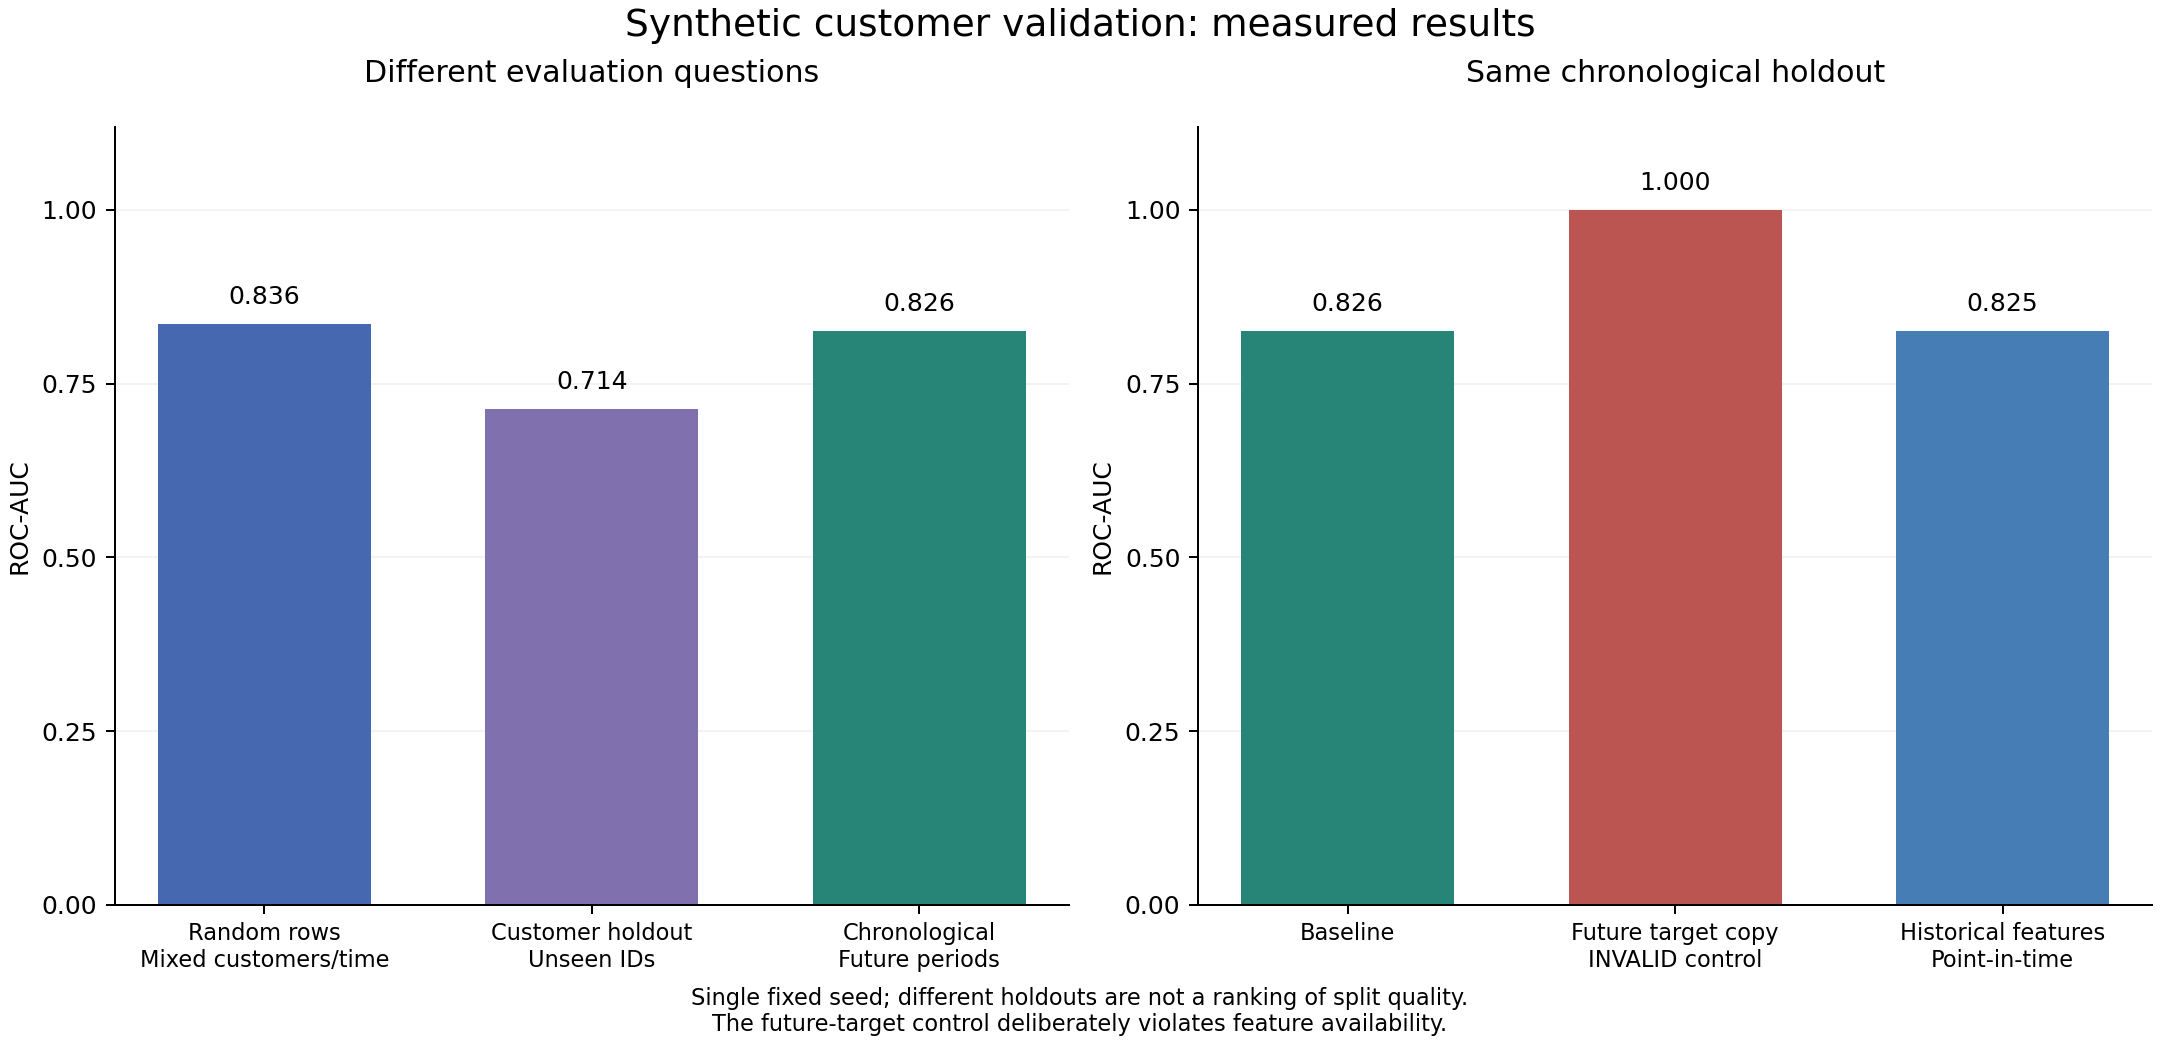

In [4]:
from IPython.display import Image, display

chart_path = project_root / ".cache/notebook-validation.png"
chart_path.parent.mkdir(parents=True, exist_ok=True)
plot_comparison(metrics, chart_path)
display(Image(filename=str(chart_path)))


In [5]:
from src.validation_strategies import chronological_split

train, test = chronological_split(features)
assert train.label_available_time.max() <= test.snapshot_time.min()
grouped = metrics.set_index("experiment")
assert grouped.loc["customer_grouped", "customer_overlap_count"] == 0
assert grouped.loc["point_in_time", "future_feature_row_count"] == 0
assert grouped.loc["future_feature", "future_feature_row_count"] > 0
print("Customer isolation, label maturity and provenance checks passed.")


Customer isolation, label maturity and provenance checks passed.


## Interpretation

Customer ID is one-hot encoded, so repeated known customers let the baseline learn stable latent propensities. Unknown IDs use the encoder's ignore behaviour. Grouped validation therefore answers a different question from row validation. Corrected historical features need not beat the chronological baseline. The feature store can incorporate newly arrived historical outcomes during the holdout; the fitted model does not change. These single-seed results are a constructed demonstration, not real-world performance estimates or confidence intervals.